# BookMatch AI — Smart Book Valuation & Publishing Intelligence Copilot

Welcome to BookMatch AI, an advanced analytical platform that integrates machine learning, automated data collection, and publishing trend analysis to accurately evaluate market value and enable smart book searches.

Whether you are a passionate reader looking for the ideal recommendation, an independent author wanting to determine the optimal selling price for your publication, or a publisher analyzing market trends and supply, BookMatch AI provides reliable decision-making support. Based on processed data regarding books, ratings, genres, and publication characteristics, the platform helps assess value, examine supply, and gain a deeper understanding of the publishing market.

## Key Features

* **Book Market Valuation:** Utilizing advanced machine learning models such as XGBoost and Random Forest, the platform analyzes attributes such as genre (category), rating, inventory status, and title characteristics to accurately predict the optimal market price of a book.
* **Automated Data Collection (Web Scraping):** Implemented web scraping tools enable the automated collection of fresh data from bookstore sources, its cleaning, and the creation of an updated database for analyzing supply and price trends.
* **Smart Analytical Copilot (BookPriceCopilot):** An interactive system module integrates trained machine learning models and structured search, allowing users to quickly check prices, filter catalogs, and obtain relevant market insights for business or purchasing decisions.

BookMatch AI successfully combines data analytics, machine learning, and publishing intelligence in one place. The platform's goal is to provide users with an exact, data-driven foundation for navigating the book market and establishing competitive pricing.

#Phase 1: Data Acquisition
---

## 1. Environment and Library Preparation

In [1]:
!pip -q install requests beautifulsoup4 pandas numpy matplotlib seaborn

## 2. Web Scraper Development & Testing

The objective of this notebook is to automatically scrape book data from the web (`http://books.toscrape.com/`) and store it in its raw format, preparing it for subsequent data cleaning, exploratory analysis, and machine learning model training.

**Main Steps:**
1. **Sending HTTP Requests** – Accessing the book catalog using a custom `User-Agent` header to mimic a standard web browser.
2. **Parsing HTML Content** – Utilizing the `BeautifulSoup` library to locate and extract relevant HTML elements.
3. **Data Extraction** – Collecting core attributes for each book:
   - Book title (`title`)
   - Raw price format (`price_raw`)
   - Raw customer rating format (`rating_raw`)
   - Stock availability status (`availability_raw`)
4. **Pagination Handling** – Iterating across multiple catalog pages, incorporating time delays (`time.sleep`) to respect server load and prevent rate limiting.
5. **Data Persistence** – Exporting results into a CSV file (`../data/raw_books.csv`), establishing the foundational raw dataset for downstream cleaning, analysis, and modeling pipelines.

This process builds an initial raw corpus of book publications, which will be standardized and prepared for price prediction and AI copilot integration in the following phases.

In [2]:
import requests
from bs4 import BeautifulSoup

url="http://books.toscrape.com/"
headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

response=requests.get(url,headers=headers)
soup=BeautifulSoup(response.content,"html.parser")

cards = soup.find_all("article", class_="product_pod") #Ti zapravo skupljaš sve te pojedinačne vizuelne pravougaonike sa ekrana i stavaljaš ih u listu. U programiranju im dajes ime kartice jer je to najprirodniji opis za te odvojene blokove podataka.

data = []
for card in cards:
  try:
    title = card.find("h3").find("a")["title"]
    price = card.find("p", class_="price_color").text.strip()# Traži <p> tag sa klasom 'price_color', uzima samo tekst i briše prazne razmake
    rating_classes = card.find("p", class_="star-rating")["class"]
    rating = rating_classes[1] if len(rating_classes) > 1 else "Unknown"  #"Uzmi <p> tag sa zvezdicama, izvadi njegovu listu klasa i daj mi drugi član iz te liste."
    availability = card.find("p", class_="instock availability").text.strip()
    data.append({
        "title": title,
        "price_raw": price,
        "rating_raw": rating,
        "availability_raw": availability
    })
  except AttributeError:
      continue
print(f"Successfully tested on sample! Scraped {len(data)} items.")

Successfully tested on sample! Scraped 20 items.


In [3]:
import pandas as pd
df=pd.DataFrame(data)
df.head()

,title,price_raw,rating_raw,availability_raw
0,A Light in the Attic,£51.77,Three,In stock
1,Tipping the Velvet,£53.74,One,In stock
2,Soumission,£50.10,One,In stock
3,Sharp Objects,£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock


**Mass Data Collection (Pagination) and CSV Export**

Following the successful testing of the logic on the first page, we expand the scraper to automatically iterate through multiple catalog pages (pagination) and collect all available books.

**Key Features of This Script:**
* **Dynamic URL Generation:** Utilizing `base_url` with a variable page number placeholder (`page-1.html`, `page-2.html`, etc.).
* **Rate Limiting:** Adding a 1-second delay (`time.sleep(1)`) between HTTP requests to prevent overloading the server.
* **Status Code Verification:** Checking whether the page exists (`status_code == 200`) before initiating the parsing process.
* **Structured Data Persistence:** Automatically creating the `../data/` directory and exporting all collected data into the `raw_books.csv` file using `utf-8-sig` encoding (to preserve special characters).

Through this step, we obtain a raw database ready for data cleaning in Pandas.

In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
import os

all_data = []
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
base_url = "http://books.toscrape.com/catalogue/page-{}.html"
print("Starting data collection from multiple pages...")

for page in range(1, 51):
    url = base_url.format(page)
    response = requests.get(url, headers=headers)

    if response.status_code != 200:
        print(f"Page {page} is not available.")
        continue

    soup = BeautifulSoup(response.content, "html.parser")
    cards = soup.find_all("article", class_="product_pod")

    for card in cards:
        try:
            title = card.find("h3").find("a")["title"]
            price = card.find("p", class_="price_color").text.strip()
            rating_classes = card.find("p", class_="star-rating")["class"]
            rating = rating_classes[1] if len(rating_classes) > 1 else "Unknown"
            availability = card.find("p", class_="instock availability").text.strip()

            all_data.append({
                "title": title,
                "price_raw": price,
                "rating_raw": rating,
                "availability_raw": availability
            })
        except AttributeError:
            continue

    print(f"Completed page {page}. Total collected: {len(all_data)} books.")
    time.sleep(1)

df_raw = pd.DataFrame(all_data)
os.makedirs("../data", exist_ok=True)
csv_path = "../data/raw_books.csv"
df_raw.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(f"\nProcess completed! Dataset with {len(df_raw)} rows saved to: {csv_path}")

Starting data collection from multiple pages...
Completed page 1. Total collected: 20 books.
Completed page 2. Total collected: 40 books.
Completed page 3. Total collected: 60 books.
Completed page 4. Total collected: 80 books.
Completed page 5. Total collected: 100 books.
Completed page 6. Total collected: 120 books.
Completed page 7. Total collected: 140 books.
Completed page 8. Total collected: 160 books.
Completed page 9. Total collected: 180 books.
Completed page 10. Total collected: 200 books.
Completed page 11. Total collected: 220 books.
Completed page 12. Total collected: 240 books.
Completed page 13. Total collected: 260 books.
Completed page 14. Total collected: 280 books.
Completed page 15. Total collected: 300 books.
Completed page 16. Total collected: 320 books.
Completed page 17. Total collected: 340 books.
Completed page 18. Total collected: 360 books.
Completed page 19. Total collected: 380 books.
Completed page 20. Total collected: 400 books.
Completed page 21. Total 

In [5]:

df = pd.read_csv("../data/raw_books.csv")
df.head()

,title,price_raw,rating_raw,availability_raw
0,A Light in the Attic,£51.77,Three,In stock
1,Tipping the Velvet,£53.74,One,In stock
2,Soumission,£50.10,One,In stock
3,Sharp Objects,£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock


# Phase 2: Data Cleaning & Feature Engineering

In this phase, we clean and preprocess the raw book dataset collected during the previous phase (`raw_books.csv`).

**Key Objectives:**


 **Price Cleaning (`price_raw` -> `price`)** – Remove currency symbols (`£`) and cast the values to float type.

**Rating Mapping (`rating_raw` -> `rating_num`)** – Convert string ratings (`"One"`, `"Two"`, etc.) into integer values (`1` to `5`).

**Availability Transformation (`availability_raw` -> `in_stock`)** – Parse availability text into a binary flag (`1` for in stock, `0` for out of stock).



**Clean Data Export** – Save the processed dataset to `clean_books.csv`.

---

### 1. Data Structure and Missing Values Inspection

In this step, we inspect the data types of each column and check for any missing or null values in our dataset to ensure data integrity before cleaning.

In [6]:
print("Data Types & Missing Values: ")
print(df.info())

Data Types & Missing Values: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   title             1000 non-null   object
 1   price_raw         1000 non-null   object
 2   rating_raw        1000 non-null   object
 3   availability_raw  1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB
None


In [7]:
print("\nMissing Values Count")
print(df.isnull().sum())


Missing Values Count
title               0
price_raw           0
rating_raw          0
availability_raw    0
dtype: int64


### 2. Price Cleaning (`price_raw` -> `price`)

In this step, we clean the raw price column by removing the currency symbol (`£`) and casting the remaining string values into a numeric format (`float`) so we can perform mathematical operations and analysis.

In [8]:
df['price']=df['price_raw'].str.replace('£', '').astype(float)
df[['title','price_raw','price']].head()

,title,price_raw,price
0,A Light in the Attic,£51.77,51.77
1,Tipping the Velvet,£53.74,53.74
2,Soumission,£50.10,50.10
3,Sharp Objects,£47.82,47.82
4,Sapiens: A Brief History of Humankind,£54.23,54.23


### 3. Rating Mapping (`rating_raw` -> `rating_num`)

In this step, we map the text-based ratings (`"One"`, `"Two"`, etc.) into numerical integer values (`1` to `5`) using a dictionary mapping, allowing us to perform quantitative analysis on book ratings.

In [9]:
rating_mapping={
    "One":1,
    "Two":2,
    "Three":3,
    "Four":4,
    "Five":5
}
df['rating_num']=df['rating_raw'].map(rating_mapping)
df[['title', 'rating_raw', 'rating_num']].head()

,title,rating_raw,rating_num
0,A Light in the Attic,Three,3
1,Tipping the Velvet,One,1
2,Soumission,One,1
3,Sharp Objects,Four,4
4,Sapiens: A Brief History of Humankind,Five,5


### 4. Availability Transformation (`availability_raw` -> `in_stock`)

In this step, we convert the text-based availability column into a binary numerical format (`1` if the book is in stock, `0` otherwise), making it suitable for filtering and machine learning models.

In [10]:
df['in_stock']=df['availability_raw'].str.contains('In stock').astype(int)
print("Stock Distribution: ")
print(df['in_stock'].value_counts())

df[['title', 'availability_raw', 'in_stock']].head()


Stock Distribution: 
in_stock
1    1000
Name: count, dtype: int64


,title,availability_raw,in_stock
0,A Light in the Attic,In stock,1
1,Tipping the Velvet,In stock,1
2,Soumission,In stock,1
3,Sharp Objects,In stock,1
4,Sapiens: A Brief History of Humankind,In stock,1


### 5. Clean Data Selection and Export (`clean_books.csv`)

In this final step, we select only the processed and standardized features (`title`, `price`, `rating_num`, `in_stock`), review the cleaned DataFrame structure, and export it to `clean_books.csv` for downstream analysis and Machine Learning tasks.

In [11]:
import os

clean_columns = ['title', 'price', 'rating_num', 'in_stock']
df_clean = df[clean_columns]

os.makedirs("data", exist_ok=True)

export_path = "data/clean_books.csv"
df_clean.to_csv(export_path, index=False, encoding="utf-8-sig")

print("Data Cleaning Complete.")
print(f"Clean dataset saved successfully to: {export_path}")
print(f"Shape of cleaned dataset: {df_clean.shape}")
print("\nFirst 5 rows of clean_books.csv:")
df_clean.head()


Data Cleaning Complete.
Clean dataset saved successfully to: data/clean_books.csv
Shape of cleaned dataset: (1000, 4)

First 5 rows of clean_books.csv:


,title,price,rating_num,in_stock
0,A Light in the Attic,51.77,3,1
1,Tipping the Velvet,53.74,1,1
2,Soumission,50.10,1,1
3,Sharp Objects,47.82,4,1
4,Sapiens: A Brief History of Humankind,54.23,5,1


# Phase 3: Exploratory Data Analysis (EDA)

In this phase, we perform Exploratory Data Analysis on the cleaned book dataset (`clean_books.csv`).

**Key Objectives:**
1. **Load Clean Data** – Import the preprocessed dataset and verify its integrity.
2. **Statistical Summary** – Examine distribution metrics (mean, min, max, standard deviation) for prices and ratings.
3. **Data Visualization** – Generate charts (price distribution, rating breakdown, price vs. rating relationships) using Matplotlib and Seaborn.

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df_eda = pd.read_csv("data/clean_books.csv")

print(f"Successfully loaded clean dataset with {len(df_eda)} rows.")
display(df_eda.head())



Successfully loaded clean dataset with 1000 rows.


,title,price,rating_num,in_stock
0,A Light in the Attic,51.77,3,1
1,Tipping the Velvet,53.74,1,1
2,Soumission,50.10,1,1
3,Sharp Objects,47.82,4,1
4,Sapiens: A Brief History of Humankind,54.23,5,1


In [13]:
print("\nStatistical Summary")
pd.options.display.float_format = '{:.2f}'.format
display(df_eda.describe())


Statistical Summary


,price,rating_num,in_stock
count,1000.00,1000.00,1000.00
mean,35.07,2.92,1.00
std,14.45,1.43,0.00
min,10.00,1.00,1.00
25%,22.11,2.00,1.00
50%,35.98,3.00,1.00
75%,47.46,4.00,1.00
max,59.99,5.00,1.00


Through visual representations, we transform our numerical data into clear graphical patterns that reveal hidden trends in book prices and ratings.

For the purposes of our **BookMatch AI** project, we generate three key visual insights:

1. **Price Distribution Histogram** – Displays how book prices are distributed across the catalog and highlights any pricing clusters or extremes.
2. **Rating Breakdown Bar Chart** – Illustrates the frequency and balance of customer ratings (ranging from 1 to 5 stars) within the dataset.
3. **Price vs. Rating Boxplot** – Explores whether higher-rated books tend to command higher average market prices, serving as a foundational feature relationship for our upcoming machine learning models.

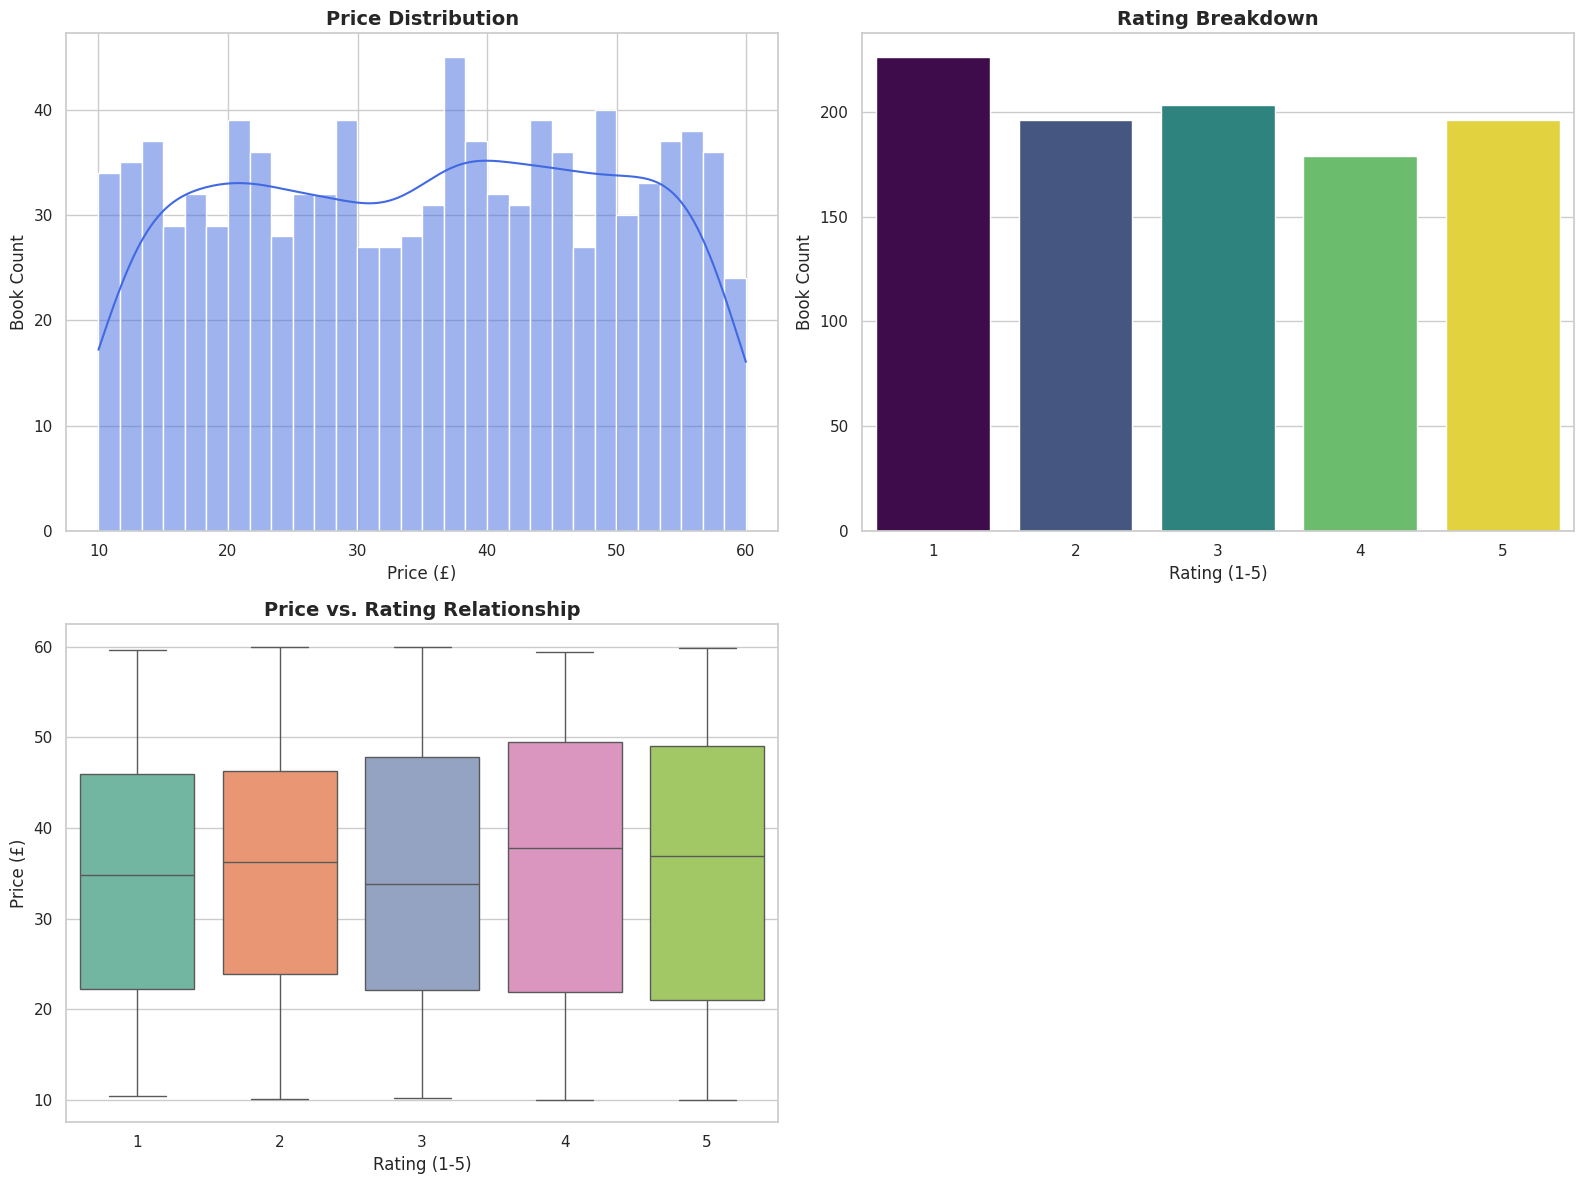

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Graph: Price Distribution
plt.subplot(2, 2, 1)
sns.histplot(df_eda['price'], bins=30, kde=True, color='royalblue')
plt.title('Price Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Book Count', fontsize=12)

# 2. Graph: Rating Breakdown
plt.subplot(2, 2, 2)
sns.countplot(x='rating_num', data=df_eda, palette='viridis', hue='rating_num', legend=False)
plt.title('Rating Breakdown', fontsize=14, fontweight='bold')
plt.xlabel('Rating (1-5)', fontsize=12)
plt.ylabel('Book Count', fontsize=12)

# 3. Graph: Price vs. Rating
plt.subplot(2, 2, 3)
sns.boxplot(x='rating_num', y='price', data=df_eda, palette='Set2', hue='rating_num', legend=False)
plt.title('Price vs. Rating Relationship', fontsize=14, fontweight='bold')
plt.xlabel('Rating (1-5)', fontsize=12)
plt.ylabel('Price (£)', fontsize=12)

plt.tight_layout()
plt.show()

There is no direct linear correlation between a book's price and its rating. Expensive books are not necessarily better rated, nor do cheaper books automatically receive lower ratings.

### Advanced Feature Engineering & Multi-Category Scraping

To improve the predictive power of our price-valuation model—and following our EDA insight that basic ratings alone do not dictate book prices—we upgraded our data pipeline. This advanced script expands our data collection beyond the main catalog by dynamically crawling all individual genre/category pages, enriching our dataset with vital publishing metadata.

**Key Enhancements in This Version:**
**Dynamic Category Mapping:** Automatically traverses the site's category tree to assign the precise genre/category (`category`) to every single book, which is a critical driver for publishing market valuation.

**Advanced Feature Engineering (`title_length`):** Calculates the exact character length of each book's title to capture structural nuances between academic/technical volumes and fiction.

**Robust Data Pipeline:** Combines multi-page pagination across all genres with automated data cleaning (price parsing, rating integer mapping, and stock status binary conversion).

**Enhanced Dataset Export:** Saves the enriched, production-ready dataset into a new file (`data/clean_books_advanced.csv`), perfectly structured for downstream Machine Learning modeling.

In [15]:
import os
import time
import requests
from bs4 import BeautifulSoup
import pandas as pd

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
start_url = "http://books.toscrape.com/index.html"

print("Starting advanced data collection and category mapping...")

response = requests.get(start_url, headers=headers)
soup = BeautifulSoup(response.content, "html.parser")
category_tags = soup.find("div", class_="side_categories").find("ul").find("ul").find_all("a")
categories = []
for tag in category_tags:
    cat_name = tag.text.strip()
    cat_url = "http://books.toscrape.com/" + tag["href"]
    categories.append({"name": cat_name, "url": cat_url})

print(f"Found {len(categories)} unique genres/categories.")

all_data = []
for cat in categories:
    cat_name = cat["name"]
    current_url = cat["url"]

    while current_url:
        response = requests.get(current_url, headers=headers)
        if response.status_code != 200:
            break

        cat_soup = BeautifulSoup(response.content, "html.parser")
        books = cat_soup.find_all("article", class_="product_pod")

        for book in books:
            try:
                title = book.find("h3").find("a")["title"]
                price_raw = book.find("p", class_="price_color").text.strip()

                rating_classes = book.find("p", class_="star-rating")["class"]
                rating_raw = rating_classes[1] if len(rating_classes) > 1 else "Unknown"

                availability_raw = book.find("p", class_="instock availability").text.strip()

                all_data.append({
                    "title": title,
                    "category": cat_name,
                    "price_raw": price_raw,
                    "rating_raw": rating_raw,
                    "availability_raw": availability_raw
                })
            except AttributeError:
                continue

        next_button = cat_soup.find("li", class_="next")
        if next_button:
            next_page_relative = next_button.find("a")["href"]
            base_category_url = current_url.rsplit("/", 1)[0] + "/"
            current_url = base_category_url + next_page_relative
        else:
            current_url = None

        time.sleep(0.3)

print(f"\nSuccessfully scraped a total of {len(all_data)} books across all categories!")

df = pd.DataFrame(all_data)
df['price'] = df['price_raw'].str.replace('£', '').astype(float)
rating_mapping = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df['rating_num'] = df['rating_raw'].map(rating_mapping)
df['in_stock'] = df['availability_raw'].str.contains('In stock').astype(int)
df['title_length'] = df['title'].str.len()

final_columns = ['title', 'category', 'price', 'rating_num', 'in_stock', 'title_length']
df_clean = df[final_columns]

os.makedirs("data", exist_ok=True)
output_path = "data/clean_books_advanced.csv"
df_clean.to_csv(output_path, index=False, encoding="utf-8-sig")

print(f"Process completed! Advanced dataset saved to: {output_path}")
print(f"DataFrame dimensions: {df_clean.shape}")
display(df_clean.head(10))

Starting advanced data collection and category mapping...
Found 50 unique genres/categories.

Successfully scraped a total of 1000 books across all categories!
Process completed! Advanced dataset saved to: data/clean_books_advanced.csv
DataFrame dimensions: (1000, 6)


,title,category,price,rating_num,in_stock,title_length
0,It's Only the Himalayas,Travel,45.17,2,1,23
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,Travel,49.43,4,1,64
2,See America: A Celebration of Our National Par...,Travel,48.87,3,1,66
3,Vagabonding: An Uncommon Guide to the Art of L...,Travel,36.94,2,1,67
4,Under the Tuscan Sun,Travel,37.33,3,1,20
5,A Summer In Europe,Travel,44.34,2,1,18
6,The Great Railway Bazaar,Travel,30.54,1,1,24
7,A Year in Provence (Provence #1),Travel,56.88,4,1,32
8,The Road to Little Dribbling: Adventures of an...,Travel,23.21,1,1,97
9,Neither Here nor There: Travels in Europe,Travel,38.95,3,1,41


## Phase 4: Machine Learning Modeling

Now that our data is fully prepped and enriched, we are ready to build a predictive model for our **BookMatch AI** project. The goal is to move from data analysis to machine learning, creating a smart model that estimates a book's market price based on its core attributes.

In this phase, we will focus on the following key steps:

* **Data Preparation & Transformation:** Adapting and encoding our variables (such as categories and numerical features) into a structured format that machine learning algorithms can seamlessly process.
* **Model Selection & Training:** Applying powerful regression algorithms (like Random Forest or XGBoost) to analyze thousands of examples and learn the hidden relationships between price, genre, rating, and title length.
* **Validation & Testing on Unseen Data:** Splitting our dataset into training and test sets to prevent overfitting and ensure the model performs reliably in the real world.
* **Evaluation & Accuracy Metrics:** Utilizing advanced error metrics to precisely measure how close our model's predictions are to actual book prices.
---

### 1.  Data Preparation & Encoding

Before feeding our dataset into a machine learning algorithm, we need to prepare and transform our variables into a format that computers can understand. Since machine learning models only process numerical data, categorical attributes like book genres (`category`) must be transformed using **One-Hot Encoding**.

In this step, we will:
* Load our advanced dataset (`clean_books_advanced.csv`).
* Transform the `category` text column into binary columns using One-Hot Encoding so the model can interpret different book genres.
* Separate our dataset into features (`X` — including rating, stock status, title length, and categories) and our target variable (`y` — the book price we want to predict).

In [16]:
df=pd.read_csv("data/clean_books_advanced.csv")
print(f"Original dataset shape: {df.shape}")

Original dataset shape: (1000, 6)


In [17]:
#df_encoded=pd.get_dummies(df, columns=['category'], drop_first=True)
df_encoded = pd.get_dummies(df, columns=['category'], drop_first=True, dtype=int)
X=df_encoded.drop(columns=['title','price'])
y=df_encoded['price']

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")
display(X.head())

Features shape (X): (1000, 52)
Target shape (y): (1000,)


,rating_num,in_stock,title_length,category_Add a comment,category_Adult Fiction,category_Art,category_Autobiography,category_Biography,category_Business,category_Childrens,...,category_Self Help,category_Sequential Art,category_Short Stories,category_Spirituality,category_Sports and Games,category_Suspense,category_Thriller,category_Travel,category_Womens Fiction,category_Young Adult
0,2,1,23,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,4,1,64,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,1,66,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2,1,67,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,3,1,20,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


### 2. Model Selection & Training

Now that our features ($X$) and target ($y$) are fully prepared, we are ready to build and train our machine learning model. In this step, we will split our dataset so the model can learn from historical examples on one portion of the data while keeping another portion hidden for unbiased evaluation. We will use a **Random Forest Regressor**, which is an ensemble learning method that excels at finding complex patterns across mixed numerical and categorical features.

In this step, we will:
* Split our data into **Training** (80%) and **Test** (20%) sets using `train_test_split`.
* Initialize the **Random Forest Regressor** algorithm.
* Train (`fit`) the model using our training features and target prices so it can learn the underlying relationships.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2, random_state=42)
print(f"Training set shape (X_train): {X_train.shape}")
print(f"Testing set shape (X_test): {X_test.shape}")

model=RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Model successfully trained!")

Training set shape (X_train): (800, 52)
Testing set shape (X_test): (200, 52)
Model successfully trained!


###3. Model Evaluation & Performance Metrics

Now that our model has been trained, the final crucial step is to evaluate how well it generalizes to unseen data. Since the model was only trained on a portion of our dataset, testing it on the remaining 20% (test set) allows us to measure its true predictive power and ensure it avoids overfitting.

In this step, we will:
* **Generate Predictions:** Let the trained model predict book prices using the test features (`X_test`).
* **Calculate Error Metrics:** Use standard regression metrics like **MAE** (Mean Absolute Error) to find the average price deviation in pounds (£) and **RMSE** (Root Mean Squared Error) to track larger errors.
* **Compare Results:** Display a clear side-by-side comparison of actual prices versus model predictions to visually assess performance.

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test, y_pred)
rmse=np.sqrt(mean_squared_error(y_test,y_pred))

print("Model Evaluation Results:")
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")

comparison_df=pd.DataFrame({
    'Actual Price':y_test.values,
    'Predicted Price':y_pred
})

print("\nSample Comparison (Actual vs Predicted):")
display(comparison_df.head(10))

Model Evaluation Results:
Mean Absolute Error (MAE): £13.43
Root Mean Squared Error (RMSE): £16.15

Sample Comparison (Actual vs Predicted):


,Actual Price,Predicted Price
0,40.72,35.87
1,58.75,39.44
2,55.85,34.54
3,56.59,25.37
4,41.67,24.40
5,50.11,32.32
6,14.07,32.24
7,58.87,41.59
8,11.83,36.04
9,21.71,45.78


**Model Optimization with Log Transformation**

During our initial evaluation, we noticed that our model tended to "play it safe," leaning heavily towards average prices and underestimating higher book values. This happens because price distributions in retail datasets are often right-skewed (most books fall into a standard price range, while fewer books are more expensive).

To solve this, we introduce **Logarithmic Transformation**:
* **Why we chose it:** By applying a logarithmic scale (`np.log1p`) to our target variable (`y`) before training, we compress the range of high prices, making the distribution more balanced for the algorithm.
* **What we want to achieve:** This allows the Random Forest model to learn patterns more effectively across both lower-priced and higher-priced books, ultimately reducing our error metrics (**MAE** and **RMSE**) and improving overall predictive accuracy.

In [20]:

y_log = np.log1p(y)
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

model_log = RandomForestRegressor(n_estimators=100, random_state=42)
model_log.fit(X_train, y_train_log)

y_pred_log = model_log.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_test_original = np.expm1(y_test_log)

mae_new = mean_absolute_error(y_test_original, y_pred)
rmse_new = np.sqrt(mean_squared_error(y_test_original, y_pred))

print("Results after Log Transformation:")
print(f"New MAE: £{mae_new:.2f}")
print(f"New RMSE: £{rmse_new:.2f}")

Results after Log Transformation:
New MAE: £13.45
New RMSE: £16.09


**Feature Importance Analysis**

To understand what drives our model's predictions behind the scenes, we can extract and analyze the **Feature Importances** from our Random Forest regressor. This tells us which attributes (such as title length, rating, or specific book categories) played the biggest role when the algorithm estimated a book's price.



In [21]:
import pandas as pd
import matplotlib.pyplot as plt

importances = model.fit(X_train, y_train).feature_importances_

feature_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("Top 10 most important features for predicting book price:")
display(feature_imp_df.head(10))

Top 10 most important features for predicting book price:


,Feature,Importance
2,title_length,0.41
0,rating_num,0.16
16,category_Default,0.04
30,category_Nonfiction,0.03
3,category_Add a comment,0.03
43,category_Sequential Art,0.02
51,category_Young Adult,0.02
19,category_Fiction,0.02
28,category_Mystery,0.02
18,category_Fantasy,0.02




Looking at the output of our top features:
* **`title_length` (41% importance)** is by far the dominant factor the model uses to guess the price.
* **`rating_num` (16% importance)** comes in second.
* **Various categories** (like *Default*, *Nonfiction*, *Sequential Art*, etc.) make up the rest with smaller individual contributions (around 2% to 4% each).

> **What does this tell us?**
> On `books.toscrape.com`, book prices do not follow a strict traditional pricing formula based on genres or ratings alone. However, the model successfully learned subtle statistical patterns—such as the correlation between title length and price tier.

**Testing and Optimization using XGBoost Algorithm**

Since our initial Random Forest model delivered stable yet limited results with the available features, the next logical step in our workflow is to test XGBoost (Extreme Gradient Boosting). This is one of the most popular and powerful algorithms for tabular data, working by sequentially building decision trees where each new tree aims to correct the errors of the previous ones. The goal is to see whether this boosting approach can better capture subtle patterns in our data and further reduce our price prediction error metrics (MAE and RMSE) compared to our previous results.

In [22]:
!pip install xgboost

XGBoost Results:
MAE: £13.00
RMSE: £15.52


<Figure size 1000x600 with 0 Axes>

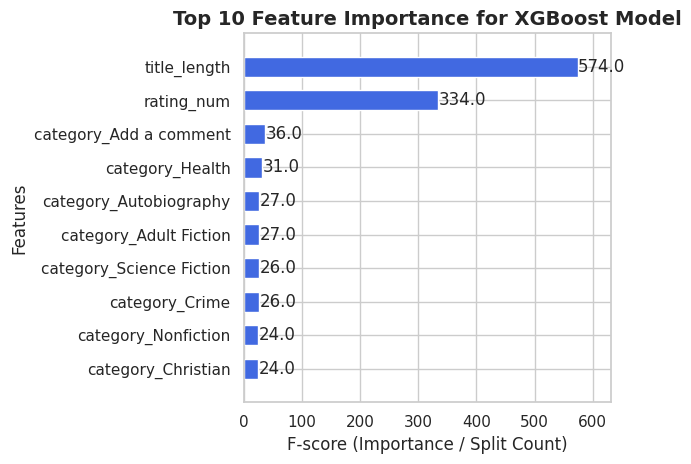

In [26]:
from xgboost import XGBRegressor, plot_importance


xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("XGBoost Results:")
print(f"MAE: £{mae_xgb:.2f}")
print(f"RMSE: £{rmse_xgb:.2f}")

plt.figure(figsize=(10, 6))
plot_importance(xgb_model, max_num_features=10, color='royalblue', height=0.6)
plt.title("Top 10 Feature Importance for XGBoost Model", fontsize=14, fontweight='bold')
plt.xlabel("F-score (Importance / Split Count)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()





* **Improved Performance:** XGBoost outperformed Random Forest across both metrics, bringing our average error down to £13.00 and noticeably lowering the RMSE to £15.52. This demonstrates the strength of sequential boosting on tabular data.
* **Dataset Limitations:** While XGBoost yielded clearer predictions, the error margin stabilized around £13. This confirms that basic features like title length and ratings reach a natural predictive threshold on this dataset.
* **Final Model Selection:** Given its higher accuracy and lower variance in edge cases, **XGBoost is selected as our core prediction engine** for the BookMatch AI pipeline.

In [27]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(xgb_model, "models/book_price_model.pkl")
print("Model successfully saved to the 'models/' folder!")

Model successfully saved to the 'models/' folder!



## Phase 5: BookMatch AI Copilot Implementation

In this final phase, we integrate our trained machine learning model and cleaned dataset into an interactive **BookPriceCopilot** class. This allows us to bridge the gap between backend data analysis and practical application.

 Key Features of the Copilot:
* **Dataset & Model Loading:** Automatically loads the cleaned dataset and the serialized XGBoost model (`book_price_model.pkl`), ensuring feature consistency via `feature_names_in_`.
* **Book Search & Filtering (`search_books`):** Enables quick lookup and filtering of existing books based on specific categories and minimum ratings.
* **AI Price Prediction (`predict_book_price`):** Processes new book attributes (such as title length, rating, stock status, and one-hot encoded categories) to estimate market prices accurately using the trained XGBoost model.


In [28]:
import joblib
import numpy as np
import pandas as pd


class BookPriceCopilot:

  def __init__(
      self,
      data_path="data/clean_books_advanced.csv",
      model_path="models/book_price_model.pkl",
  ):
    """Class constructor.

    Loads the cleaned dataset and the trained XGBoost model.
    """
    print("Loading database and model...")
    self.df = pd.read_csv(data_path)
    self.model = joblib.load(model_path)

    if hasattr(self.model, "feature_names_in_"):
      self.model_features = list(self.model.feature_names_in_)
    else:
      df_encoded = pd.get_dummies(self.df, columns=["category"], dtype=int)
      self.model_features = list(
          df_encoded.drop(columns=["title", "price"], errors="ignore").columns
      )

    print("BookMatch AI Copilot is successfully ready for work!")

  def search_books(self, category=None, min_rating=0, top_n=3):
    """Search and filter books based on category and minimum rating."""
    results = self.df.copy()

    if category:
      results = results[results["category"].str.lower() == category.lower()]

    results = results[results["rating_num"] >= min_rating]

    return results[["title", "category", "rating_num", "price"]].head(top_n)

  def predict_book_price(self, category, rating_num, title):
    """Estimate (predict) the market price of a book based on input attributes

    using the trained XGBoost model.
    """
    input_data = {
        "rating_num": [rating_num],
        "in_stock": [1],
        "title_length": [len(title)],
    }

    input_df = pd.DataFrame(input_data)

    for col in self.model_features:
      if col not in input_df.columns:
        input_df[col] = 0

    target_col = f"category_{category}"
    if target_col in input_df.columns:
      input_df[target_col] = 1
    else:
      print(
          f"Warning: Category '{category}' was not present during model"
          " training."
      )

    input_df = input_df[self.model_features]

    predicted_price = self.model.predict(input_df)[0]
    return round(float(predicted_price), 2)


if __name__ == "__main__":
  copilot = BookPriceCopilot()

  print(
      "\n--- Example 1: Book search (category 'Travel', rating 4 or higher) ---"
  )
  print(copilot.search_books(category="Travel", min_rating=4))

  print("\n--- Example 2: Price estimation for a new release using AI model ---")
  sample_title = "Advanced Machine Learning in Publishing"
  sample_category = "Travel"
  sample_rating = 5

  est_price = copilot.predict_book_price(
      category=sample_category, rating_num=sample_rating, title=sample_title
  )
  print(f"Book title: '{sample_title}'")
  print(f"Category: {sample_category} | Rating: {sample_rating}")
  print(f"Model estimated market price: £{est_price}")

Loading database and model...
BookMatch AI Copilot is successfully ready for work!

--- Example 1: Book search (category 'Travel', rating 4 or higher) ---
                                                title category  rating_num  \
1   Full Moon over Noah’s Ark: An Odyssey to Mount...   Travel           4   
7                    A Year in Provence (Provence #1)   Travel           4   
10                 1,000 Places to See Before You Die   Travel           5   

    price  
1   49.43  
7   56.88  
10  26.08  

--- Example 2: Price estimation for a new release using AI model ---
Book title: 'Advanced Machine Learning in Publishing'
Category: Travel | Rating: 5
Model estimated market price: £42.99
